In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../mouse-control/src'))
from utils_mouse_control import read_utils as read_utils_control

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

<module 'utils.analysis_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/analysis_utils.py'>

In [3]:
organism = 'mouse'

ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ss'
manual = False
full = False

save = False

In [4]:
# file_ids = list(range(0, 8+1))
file_ids = [2]

In [5]:
filenames = analysis_utils.read_filenames(organism, file_ids)

model_path = read_utils.get_model_path()

metadata = (filenames, model_path, model_variant, data_variant, manual, full)

In [6]:
((boms_spn, _, _, _, _, _, _),
 (hgms_spn, _, _, _, _, _, _)) = analysis_utils.read_predictionss(*metadata)

In [7]:
neuron_scores = analysis_utils.assemble_scores(boms_spn, hgms_spn)

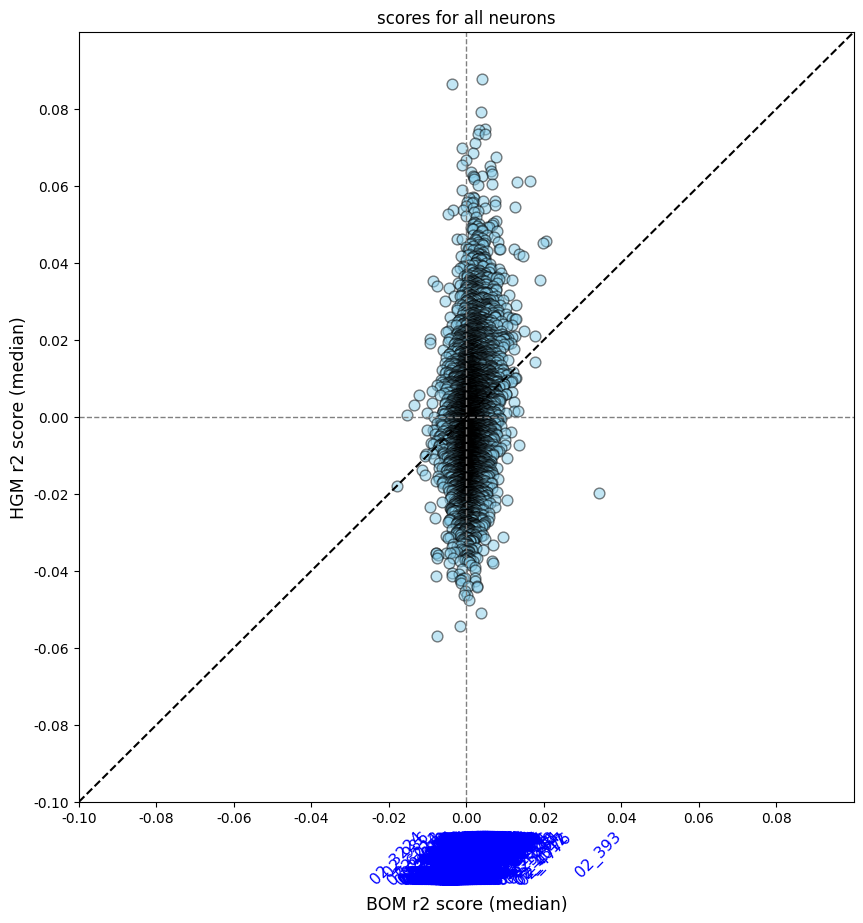

In [22]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=(-0.1, 0.1, -0.1, 0.1), force_medians=False, horizontal_bps=False,
	save_path=f'../../out/plots/scores/{model_variant}_scores_all' if save else None
)

# shuffle control

In [9]:
shuffle_scores = list()
for shuffle_id in range(100):
	((boms_spn, _, _, _, _, _, _),
	 (hgms_spn, _, _, _, _, _, _)) = analysis_utils.read_scoress(filenames, read_utils_control.get_model_path(shuffle_id), model_variant, data_variant, manual, full)
	shuffle_scores.append((boms_spn, hgms_spn))
neuron_scores_shuffle = [analysis_utils.assemble_scores(*shuffle_scores[i]) for i in range(100)]
shuffle_scores = None  # clear memory
neuron_scores_shuffle_merged = ai_slob.merge_neuron_scores_per_shuffle(neuron_scores_shuffle)

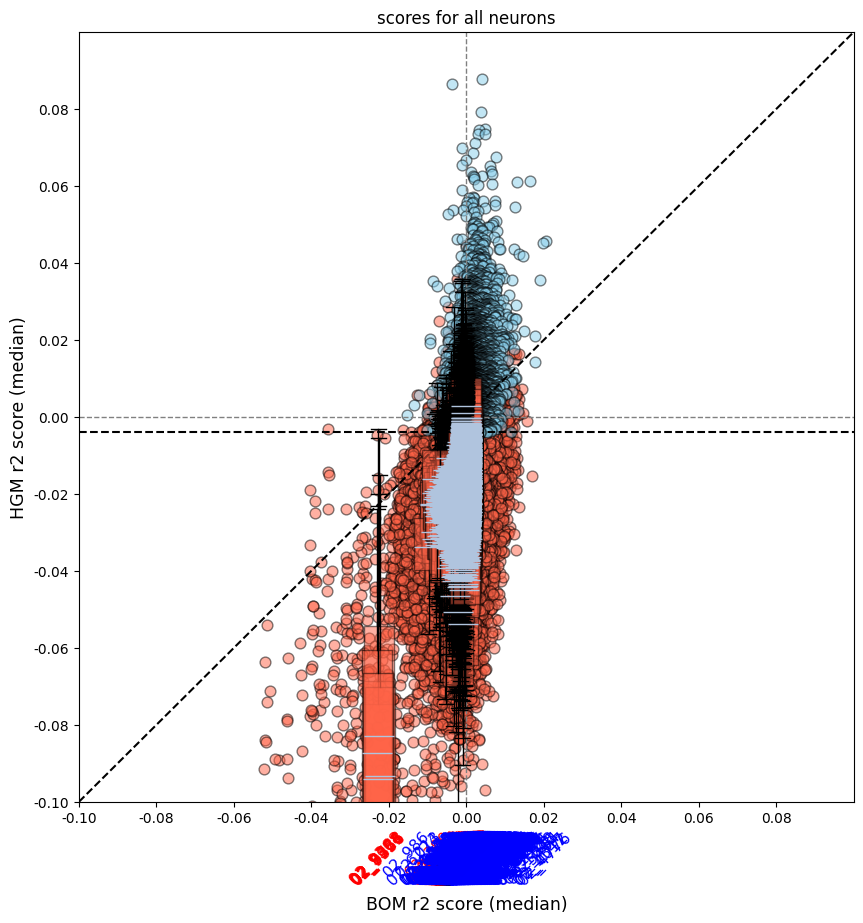

In [21]:
plot_utils.plot_performance_plot(
	neuron_scores, neuron_scores_shuffle_merged,
	title='scores for all neurons', limits=(-0.1, 0.1, -0.1, 0.1), force_medians=False, horizontal_bps=False,
)

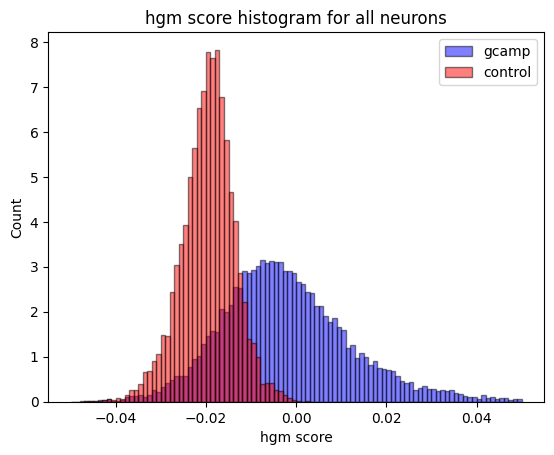

In [18]:
plot_utils.plot_performance_histogram(neuron_scores,
									  neuron_scores_shuffle_merged,
									  bins=100, range=(-0.05, 0.05),
									  title='hgm score histogram for all neurons')

In [12]:
# compute HGM percentiles (default agg: mean of flattened array)
percentiles_hgm = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='hgm'
)

# compute BOM percentiles
percentiles_bom = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='bom'
)

# print top 10 ID'd neurons by HGM percentile
top10 = list(percentiles_hgm.items())[:]
for label, pct in top10:
	print(f"{label}: {pct:.1f} percentile")

02_9368: 100.0 percentile
02_8146: 100.0 percentile
02_425: 100.0 percentile
02_7412: 100.0 percentile
02_2214: 100.0 percentile
02_2174: 100.0 percentile
02_5548: 100.0 percentile
02_7331: 100.0 percentile
02_7204: 100.0 percentile
02_7504: 100.0 percentile
02_1408: 100.0 percentile
02_5477: 100.0 percentile
02_8097: 100.0 percentile
02_5403: 100.0 percentile
02_233: 100.0 percentile
02_023: 100.0 percentile
02_1246: 100.0 percentile
02_030: 100.0 percentile
02_6505: 100.0 percentile
02_8307: 100.0 percentile
02_1107: 100.0 percentile
02_6212: 100.0 percentile
02_1348: 100.0 percentile
02_3761: 100.0 percentile
02_4429: 100.0 percentile
02_5545: 100.0 percentile
02_7686: 100.0 percentile
02_1057: 100.0 percentile
02_1200: 100.0 percentile
02_7446: 100.0 percentile
02_7309: 100.0 percentile
02_086: 100.0 percentile
02_7398: 100.0 percentile
02_1327: 100.0 percentile
02_6203: 100.0 percentile
02_2265: 100.0 percentile
02_6246: 100.0 percentile
02_2099: 100.0 percentile
02_3736: 100.0 pe

In [13]:
# Build sorted list + OrderedDict
entries_sorted, percentiles_hgm_best = ai_slob.build_sorted_percentiles(percentiles_hgm, neuron_scores, model_index=1)

# entries_sorted is a list of tuples: (label, percentile, actual_hgm)
# percentiles_hgm_best is an OrderedDict: label -> (percentile, actual_hgm)
percentiles_hgm_best = {key: val for key, val in percentiles_hgm_best.items() if val[0] == 100}

# Quick check: print top 10
print("Top 10 by percentile (tie-breaker = actual HGM):")
for label, pct, actual in entries_sorted[:50]:
	print(f"{label}: {pct:.2f} percentile, actual_hgm = {actual:.4g}")

Top 10 by percentile (tie-breaker = actual HGM):
02_9368: 100.00 percentile, actual_hgm = 0.116
02_8146: 100.00 percentile, actual_hgm = 0.08773
02_425: 100.00 percentile, actual_hgm = 0.08653
02_7412: 100.00 percentile, actual_hgm = 0.07911
02_2214: 100.00 percentile, actual_hgm = 0.07472
02_2174: 100.00 percentile, actual_hgm = 0.07455
02_5548: 100.00 percentile, actual_hgm = 0.07334
02_7331: 100.00 percentile, actual_hgm = 0.07334
02_7204: 100.00 percentile, actual_hgm = 0.071
02_7504: 100.00 percentile, actual_hgm = 0.06975
02_1408: 100.00 percentile, actual_hgm = 0.06843
02_5477: 100.00 percentile, actual_hgm = 0.06758
02_8097: 100.00 percentile, actual_hgm = 0.06665
02_5403: 100.00 percentile, actual_hgm = 0.06532
02_233: 100.00 percentile, actual_hgm = 0.06523
02_023: 100.00 percentile, actual_hgm = 0.06389
02_1246: 100.00 percentile, actual_hgm = 0.0636
02_030: 100.00 percentile, actual_hgm = 0.06317
02_6505: 100.00 percentile, actual_hgm = 0.06254
02_8307: 100.00 percentile, a

In [14]:
print('Neuron names for copying:')
print(', '.join([f'\'{label}\'' for label in percentiles_hgm_best]))

Neuron names for copying:
'02_9368', '02_8146', '02_425', '02_7412', '02_2214', '02_2174', '02_5548', '02_7331', '02_7204', '02_7504', '02_1408', '02_5477', '02_8097', '02_5403', '02_233', '02_023', '02_1246', '02_030', '02_6505', '02_8307', '02_1107', '02_6212', '02_1348', '02_3761', '02_4429', '02_5545', '02_7686', '02_1057', '02_1200', '02_7446', '02_7309', '02_086', '02_7398', '02_1327', '02_6203', '02_2265', '02_6246', '02_2099', '02_3736', '02_6502', '02_6254', '02_5565', '02_236', '02_130', '02_7489', '02_7316', '02_6449', '02_372', '02_1102', '02_7829', '02_8871', '02_5448', '02_5486', '02_974', '02_7244', '02_4740', '02_7569', '02_2101', '02_7249', '02_8317', '02_1062', '02_2068', '02_3796', '02_7525', '02_1027', '02_1189', '02_3967', '02_3368', '02_2988', '02_8242', '02_1321', '02_8195', '02_6231', '02_6237', '02_7355', '02_5550', '02_4776', '02_1545', '02_5341', '02_6601', '02_5483', '02_4012', '02_2011', '02_7260', '02_3973', '02_6210', '02_462', '02_3803', '02_215', '02_90

In [15]:
importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

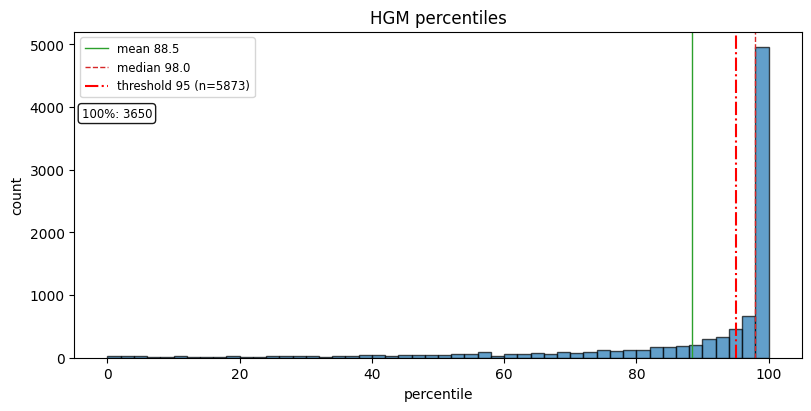

(array([  21.,   20.,   22.,   18.,   11.,   27.,   17.,   11.,   15.,
          22.,   19.,   18.,   21.,   23.,   27.,   31.,   15.,   26.,
          30.,   38.,   36.,   32.,   44.,   43.,   41.,   46.,   54.,
          63.,   88.,   33.,   61.,   63.,   71.,   60.,   96.,   75.,
          99.,  116.,  115.,  119.,  122.,  174.,  177.,  193.,  207.,
         305.,  337.,  462.,  673., 4955.]),
 array([  0.,   2.,   4.,   6.,   8.,  10.,  12.,  14.,  16.,  18.,  20.,
         22.,  24.,  26.,  28.,  30.,  32.,  34.,  36.,  38.,  40.,  42.,
         44.,  46.,  48.,  50.,  52.,  54.,  56.,  58.,  60.,  62.,  64.,
         66.,  68.,  70.,  72.,  74.,  76.,  78.,  80.,  82.,  84.,  86.,
         88.,  90.,  92.,  94.,  96.,  98., 100.]))

In [16]:
ai_slob.plot_percentile_hist(percentiles_hgm, bins=50, title='HGM percentiles', threshold=95)

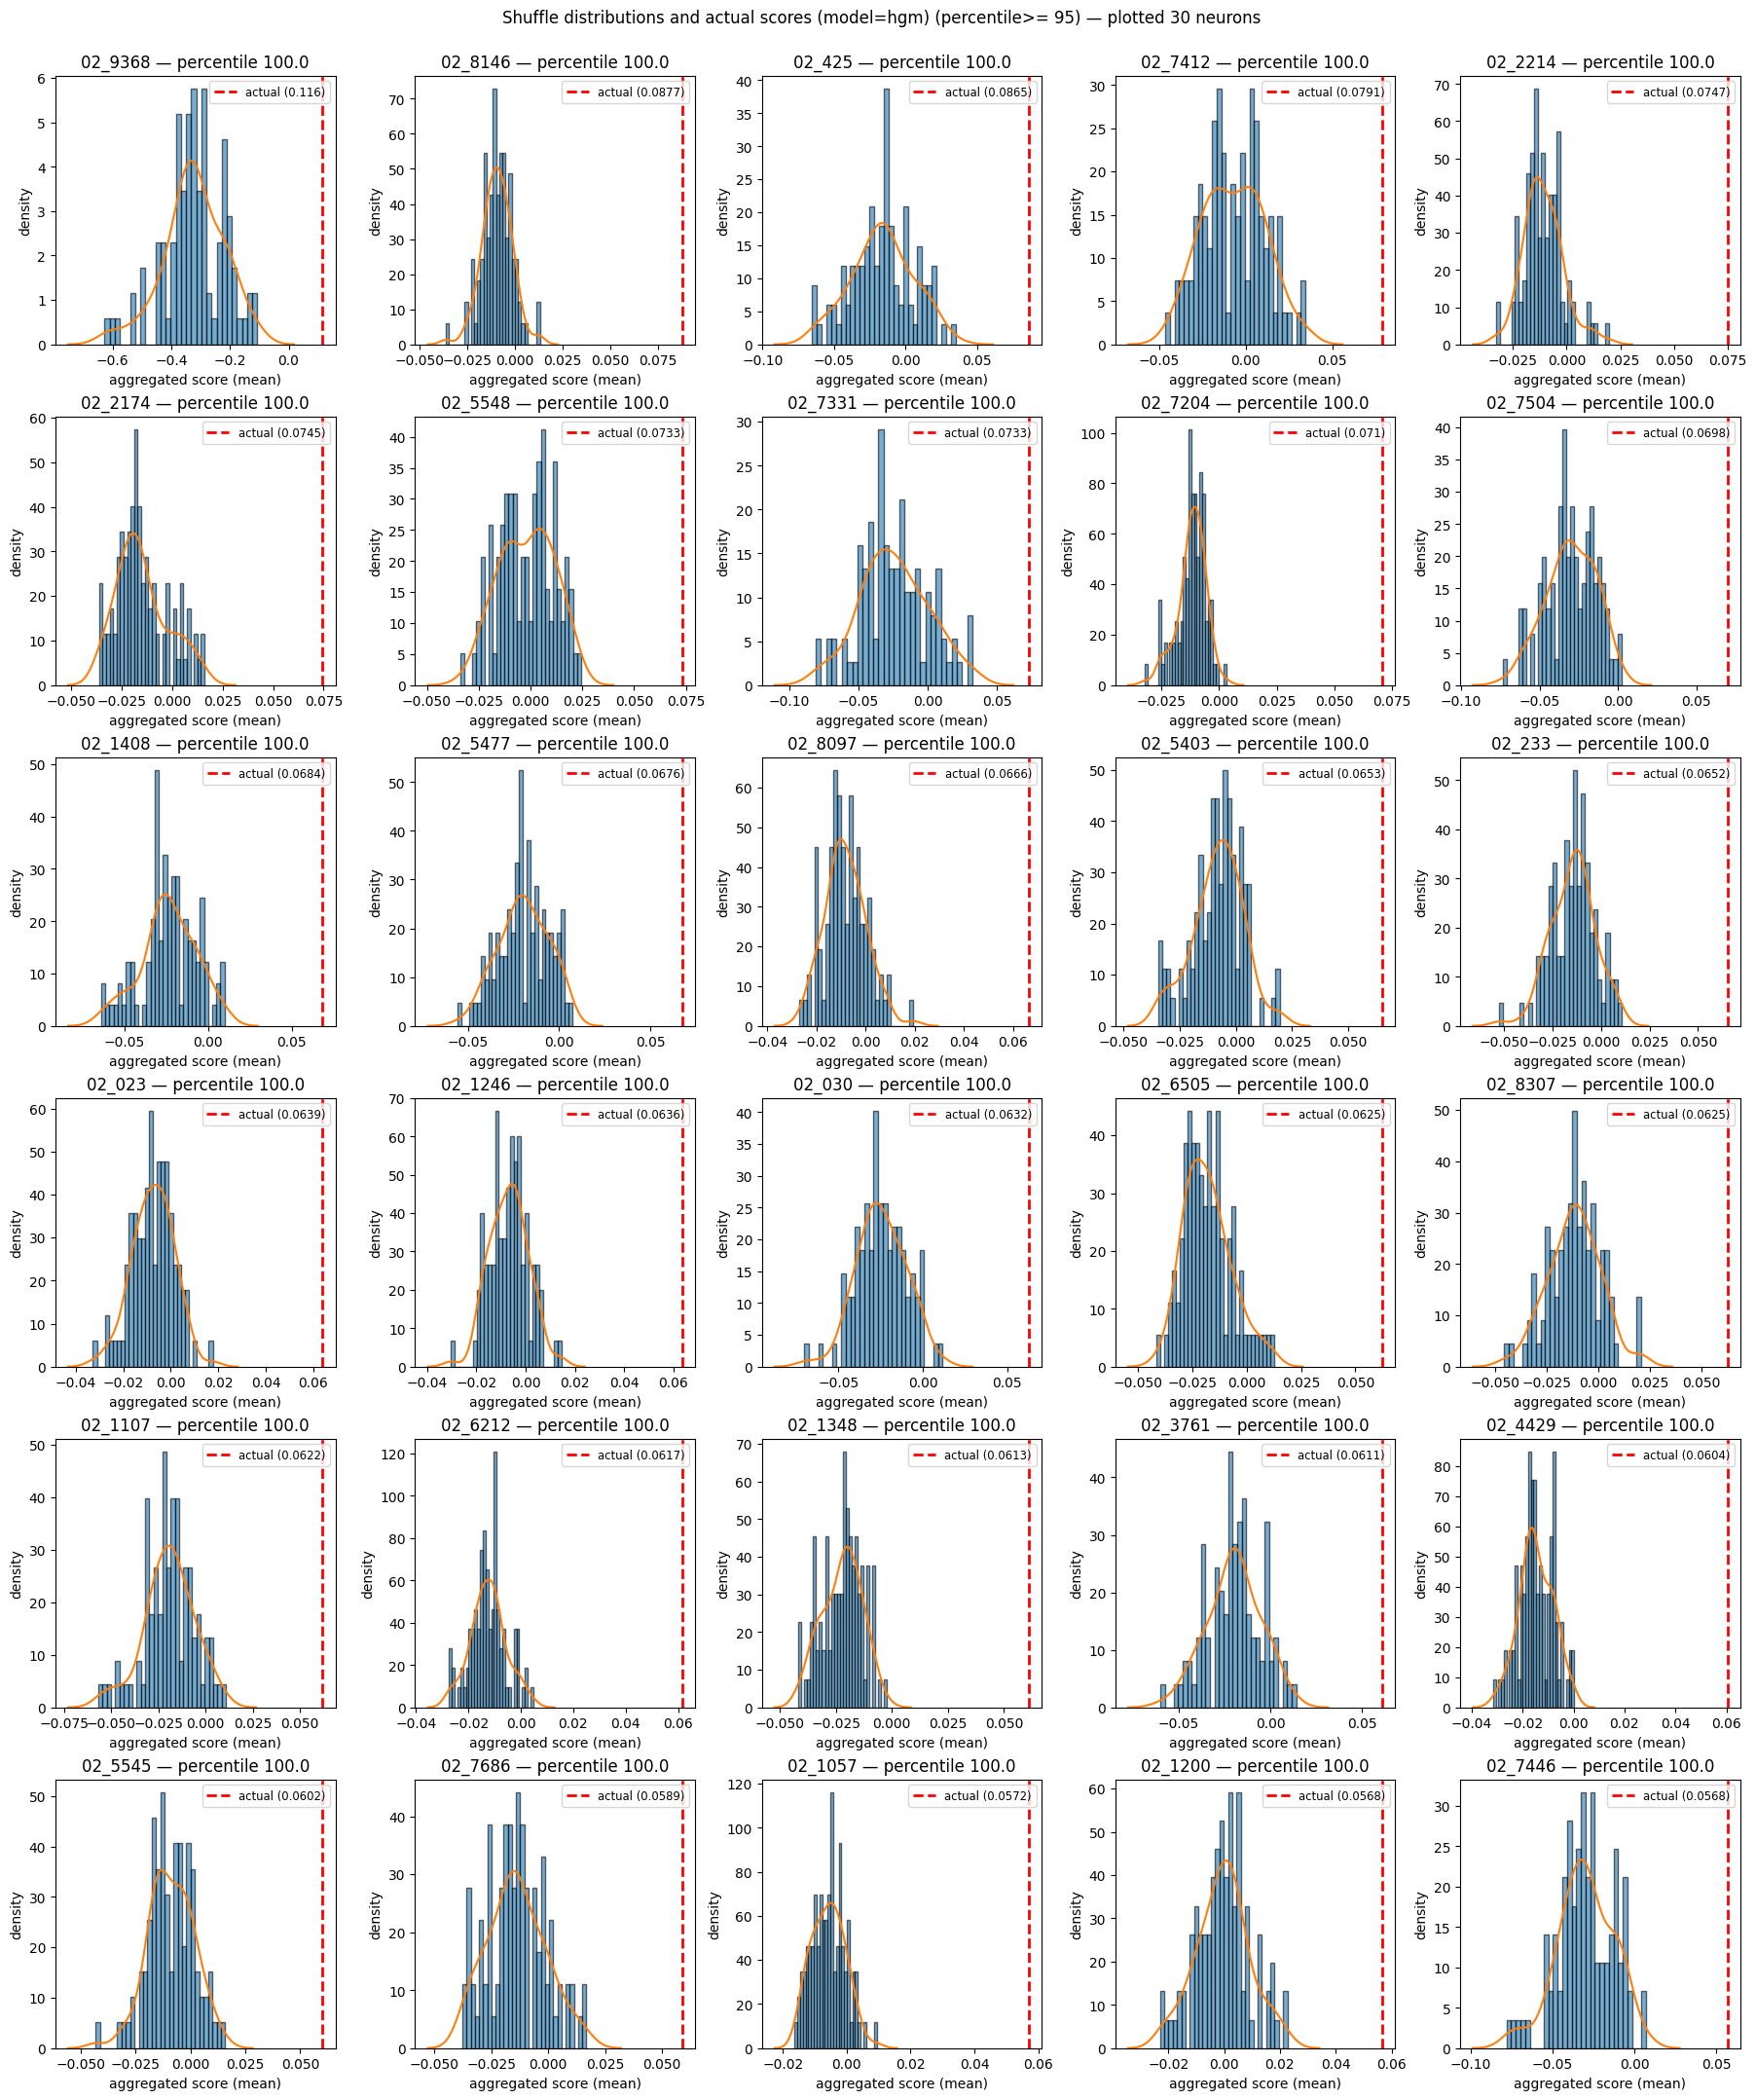

Plotted neurons: None


In [17]:
# Example usage: plots the top-10 neurons by actual HGM score
chosen = ai_slob.plot_first_n_neurons(neuron_scores, neuron_scores_shuffle, model='hgm', n=30, neuron_labels=percentiles_hgm_best.keys())
print("Plotted neurons:", chosen)

# If you want the literal insertion-order 'first 10 keys' instead, call:
# first10_insertion_order = list(neuron_scores.keys())[:10]
# chosen = plot_first_n_neurons(neuron_scores, neuron_scores_shuffle, model='hgm', neuron_labels=first10_insertion_order)